---
title: "Tsotsis et al. (1992): packed-bed catalytic membrane reactor, conversion beyond equilibrium"
description: "Whether the isothermal packed-bed catalytic membrane reactor model Tsotsis et al. print, with Knudsen permeation of every species and closed by named assumptions, can produce the model curves they plot for any permeance and any rate constant, in particular the rise of conversion with residence time in Fig. 3b."
categories: [sec:H, struct:S7, tier:T1, data:tier4, phase:gas-solid]
date: 2026-11-28
---

# Tsotsis et al. (1992): packed-bed catalytic membrane reactor

**Catalog ID:** `H1.5` · **Structures:** `S7` (two coupled plug-flow channels) · **Tier:** T1

Tsotsis, Champagnie, Vasileiadis, Ziaka and Minet dehydrogenated ethane in a porous
alumina membrane tube packed with catalyst, swept argon along the outside, and reported
conversions above the equilibrium lines they drew. They printed a general model (eqs. 1 to
6), fitted its isothermal version with the layer thickness as the only adjustable
parameter, and plotted model curves beside their data. They printed no kinetics and no
permeances. This page closes the printed model with named assumptions and asks whether
any value of the two missing scales, the permeation number $\Pi$ and the Damkohler number
$Da$, produces the plotted model curves, above all the rise of conversion with residence
time in Fig. 3b; it first recomputes every equilibrium line the figures carry, because
"beyond equilibrium" and the pressure basis rest on them.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.10"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "H1.5-tsotsis-packed-bed-membrane-reactor"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. pymrm contributes the reactor solve (two upwind channels, BlockLayout, NumJac,
# newton, compute_boundary_values) and the checks (find_roots, observed_orders); the
# equilibrium algebra, the thermodynamics and the figure reading are numpy and scipy.
import contextlib
import io
import re
from dataclasses import dataclass, replace

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta
from model import (ATM, PSI, Case, LocalEquilibrium, MembraneReactor, Thermo, conversion,
                   delta_H, drain_function_ivp, exchange_tube_ethane, k_of_xeq, knudsen_d,
                   ln_K, molar_masses, packed_bed_x, q_knudsen, relaxation_factor,
                   smr_equilibrium, solve_ivp_reactor, source, xeq)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])


def fill(text, **v):
    """Fill ``<<name:fmt>>`` in ``text`` from ``v``."""
    def sub(m):
        name, _, fmt = m.group(1).partition(":")
        return format(v[name], fmt)
    return re.sub(r"<<([^<>]+)>>", sub, text)


def say(text, **v):
    """Prose whose numbers are written by code, so they cannot drift."""
    display(Markdown(fill(text, **v)))

## Background

A membrane reactor removes a product through the wall while the reaction runs, so an
equilibrium-limited reaction can pass the conversion a closed reactor reaches. Palladium
passes hydrogen only (page `H1.4`); a porous ceramic passes every gas, by Knudsen diffusion
in pores of a few nanometres, hydrogen only about four times faster than ethane. Tsotsis
et al. ran ethane dehydrogenation, $\mathrm{C_2H_6 \rightleftharpoons C_2H_4 + H_2}$, at 500
to 625 C in a Membralox alumina tube (40 A pores in the top layer), the tube "also wet
impregnated with hexachloroplatinic acid" and the bed made of particles 0.1 to 0.15 cm in
diameter (p. 2905), argon sweep on the shell side, and wrote (p. 2907, quoted from the page
image):

> "The conversion shown in Fig. 2b, already higher than equilibrium, can be improved
> further by increasing the sweep ratio, the residence time or decreasing the tubeside
> pressure, see Fig. 3."

and, about the fit (p. 2907): "The isothermal version of the PBCMR model was used to fit the data
(the model results are the solid line) using the thickness of the permselective layer as the
only adjustable parameter. The thickness value used was 10$\mu$m, which is different from the
nominal thickness of the first microporous layer (see Champagnie, 1991), but still a reasonable
value given the uncertainties involved in the measurement of the layer's thickness and some
expected contribution of the second layer both in terms of activity and resistance to flow. Over
a broad range of conditions the model performed reasonably
well, see for example Fig. 2 which shows the conversion vs. temperature for both dilute
and dense feed conditions." The model curves are therefore the paper's claim about its
own model, and that claim is what this page tests: not the measurements, not the
authors' kinetics (which the paper does not give, "go beyond the scope and size of this
conference paper", p. 2906).

A Knudsen wall at a fixed pressure difference also passes ethane. With the tube at 30 psi
and the shell at 15 psi, the tube loses gas of every kind, and at a large enough permeance
it empties into the shell before its end. That cap, not the kinetics, decides how high the
model can go.

## The published model

The paper's eqs. 1, 3 and 5 (p. 2904 to 2905): steady diffusion with reaction in the
membrane wall (eq. 1), and plug-flow balances of each species on the tube side (eq. 3)
and the shell side (eq. 5), coupled through the wall flux $2\pi D_{je}(r\,dC_j^m/dr)$ at
$R_1$ and $R_2$. Eqs. 2, 4 and 6 are the energy balances; the paper fits the isothermal
version, as here. Without reaction in the wall, eq. 1 makes $C_j^m$ linear in $\ln r$
and the flux per unit length $2\pi D_{je}(C_j^F - C_j^P)/\ln(R_2/R_1)$. In flows scaled by
the total feed and the axial coordinate $\zeta = z/L$ (EQUATIONS E8):

$$\frac{dn_j^F}{d\zeta} = -\Pi\,q_j\,(y_j^F - \beta y_j^P) + \nu_j\,Da\,\Big(y_E^F - \frac{y_Y^F y_H^F}{K'}\Big),
\qquad \frac{dn_j^P}{d\zeta} = +\Pi\,q_j\,(y_j^F - \beta y_j^P)\;\big[+\,\nu_j\,Da\,(\beta y_E^P - \beta^2 y_Y^P y_H^P/K')\big]$$

with $\beta = P^P/P^F$, $K' = K_p/P^F$, $q_j = (M_E/M_j)^{1/2}$ (Knudsen), $\Pi =
2D_{Ee}\tau/(R_1^2\ln(R_2/R_1))$ and $Da = \eta k \tau$, $\tau$ the tube residence time. The
bracket is the shell-reaction variant. Inlets: the feed in the tube, $Pr$ mol argon per
mol feed in the shell, cocurrent (the paper's Fig. 1).

| symbol | meaning | code |
|---|---|---|
| $n_j^F$, $n_j^P$ | tube and shell flows of C2H6, C2H4, H2, Ar over the feed | state `(n_z, 8)` |
| $\Pi$, $Da$ | permeation and Damkohler numbers (the two free scales) | `Pi`, `Da` |
| $q_j$ | Knudsen permeance ratio to ethane | `Case.q` |
| $\beta$, $K'$ | pressure ratio, $K_p/P^F$ | `Case.beta`, `Case.Kred` |
| $Pr$ | sweep ratio | `Case.Pr` |

Conversion (the paper does not define it, M5): D1 = ethylene leaving both sides over
ethane fed (default); D2 = tube outlet $n_Y/(n_E+n_Y)$; D4 = $1 - n_E^F/n_{E0}$. Limits
used for validation (E16, E17): $Da\to\infty$ (local equilibrium in the tube; the model is
then autonomous in $s = \Pi\zeta$), $\Pi = 0$ (packed bed), and $q_j = 1$, $Da = 0$ (pure
exchange, closed form; with $\beta < 1$ the tube drains at $\Pi_d = 1/(1-\beta)$).

## Parameters and assumptions

Printed values (file `tsotsis-1992-printed-numbers.csv`, strings as printed): tube 0.7 cm
I.D., 25 cm; top layer 40 A pores, fitted thickness 10 um; dense feed 83.4 % C2H6, 8.3 %
H2, 8.3 % Ar; dilute feed 8.7 %, 4.4 %, 86.9 %; Figs. 2 and 3: sweep ratio 1.0,
$\tau$ = 2.0 s, $P_T^F$ = 30 psi, $P_T^P$ = 15 psi, Fig. 3 at 550 C. Named assumptions
(EQUATIONS A1 to A8): A1 mass-action reversible rate, lumped $k$; A2 Knudsen ratios for
every species, $\Pi$ free; A3 sweep ratio molar; A4 $\tau$ at tube conditions; A5 layer
on the tube side; A6 no reaction in the wall, although eq. 1 carries one and the tube is
Pt-impregnated (the shell-reaction variant is taken to bracket it, not shown); A7
$K_p$ from Smith, Van Ness and Abbott, Tables C.1 and C.4 (`svna-thermo.csv`); A8
isothermal, no pressure drop (the paper adds Ergun-type equations, p. 2905). "psi" is read as gauge (the default) or absolute: both are
carried. No kinetic constant, permeance, $\varepsilon/\tau_m$ or layer thickness is the
paper's; none is claimed.

In [3]:
PN = load_data("tsotsis-1992-printed-numbers.csv", page=PAGE, dtype=str)
PRINTED = dict(zip(PN["item"], PN["printed"]))


def pf(item):
    """A printed number as a float (the CSV keeps the printed strings)."""
    return float(PRINTED[item])


TH_ROWS = load_data("svna-thermo.csv", page=PAGE)
TABLE = {r.species: (r.A, r.B, r.C, r.D, r.dHf298_J_mol, r.dGf298_J_mol) for r in TH_ROWS.itertuples()}
DENSE = np.array([pf("dense_C2H6"), 0.0, pf("dense_H2"), pf("dense_Ar")]) / 100   # p. 2906
DILUTE = np.array([pf("dilute_C2H6"), 0.0, pf("dilute_H2"), pf("dilute_Ar")]) / 100
P_TUBE, P_SHELL = pf("P_tube"), pf("P_shell")             # psi, basis not printed (M1)
TAU2 = pf("tau")                                         # s
TK = pf("T_fig3") + 273.15                               # K
R1 = pf("membrane_id") / 2 * 1e-2                         # m
DELTA = pf("layer_thickness") * 1e-6                      # m
D_PORE = pf("pore_diameter_layer1") * 1e-10               # m
SMR_P = pf("smr_P_reaction")                              # psig
PI_T, DA_T = 0.5, 0.1                                    # test condition T of the check values
EPS_D = 0.01                                             # drainage threshold (E18)
V_LO, V_HI = 0.18, 0.30                                  # Fig. 3b verdict thresholds (pt), fixed in the plan

## The data

Seven digitised figures, one CSV each with a sidecar (`tsotsis-1992-fig2a.csv` to
`-fig4b.csv`): the model line, both equilibrium lines and the measured symbols of Figs.
2a, 2b, 3a, 3b and 3c, and the calculated equilibrium line of Figs. 4a and 4b, read from
300 ppi renders of the scan (no image is stored). Each sidecar states its axis
calibration residual and the reading error, max(calibration residual, half line width),
doubled for one-sided or masked reads and for symbols on a line. The figure values are
data with an uncertainty. The Fig. 4 symbols are not digitised. Also: the printed numbers,
the thermodynamic table (cited textbook data), and `check_values.csv`, values of the
page's functions at a test condition T computed by a separate route (not data about the
world). No dataset is borrowed from another page.

In [4]:
FIG = {k: load_data(f"tsotsis-1992-fig{k}.csv", page=PAGE) for k in ("2a", "2b", "3a", "3b", "3c", "4a", "4b")}
for k in ("2a", "3b"):
    print(cite_data(load_meta(f"tsotsis-1992-fig{k}.csv", page=PAGE)))
RE = {k: float(FIG[k].query("sides == 2 and quality == 'clean'")["reading_error_pct"].min()) for k in FIG}
print("reading error (points of conversion):", {k: round(v, 3) for k, v in RE.items()})

Tsotsis, T. T.; Champagnie, A. M.; Vasileiadis, S. P.; Ziaka, Z. D.; Minet, R. G. (1992) — Chemical Engineering Science 47(9-11), 2903-2908 — doi:10.1016/0009-2509(92)87149-K — digitised from Figure 2a (p. 2906): conversion vs temperature, dilute feed, sweep ratio 1.0, tau = 2.0 s, P_T^F = 30 psi, P_T^P = 15 psi
Tsotsis, T. T.; Champagnie, A. M.; Vasileiadis, S. P.; Ziaka, Z. D.; Minet, R. G. (1992) — Chemical Engineering Science 47(9-11), 2903-2908 — doi:10.1016/0009-2509(92)87149-K — digitised from Figure 3b (p. 2907): conversion vs tube-side residence time, dense feed, T = 550 C, sweep ratio 1.0, P_T^F = 30 psi, P_T^P = 15 psi
reading error (points of conversion): {'2a': 0.209, '2b': 0.157, '3a': 0.056, '3b': 0.042, '3c': 0.056, '4a': 0.251, '4b': 0.204}


## PyMRM implementation

`model.MembraneReactor`: the state is `(n_z, 8)`, a `BlockLayout` of the tube and shell
fields `(n_z, 4)` each. Each channel convects its molar flows with a constant
unit-velocity first-order upwind operator (`construct_convflux_upwind`, `construct_div`
with $\nu = 0$), so the changing gas velocity never enters an operator; inlets are
Dirichlet values in the `bc`, outlets `{"outflow": True}`, read with
`compute_boundary_values`. The source (permeation and reaction) is pointwise and goes
through `NumJac`; `newton` solves the sparse system with a lower bound 0 on every flow.
The independent route is the same right-hand side integrated by `solve_ivp` (Radau), and
the $Da\to\infty$ limit is `model.LocalEquilibrium`, an integration in $s = \Pi\zeta$ of
the tube invariants with the tube composition at equilibrium in every section. Drainage
and every threshold are roots by `pymrm.checks.find_roots`; grid orders by
`pymrm.checks.observed_orders`.

### Check values

Before any claim the page's functions are asserted against `check_values.csv` (41 rows).

In [5]:
@dataclass(frozen=True)
class Cfg:
    """Inputs of the study; every field other than the defaults is a break-table defect."""
    cp: bool = True                 # heat-capacity terms in K_p
    h2_zero: bool = False           # dense feed without its H2 co-feed
    basis: str = "gauge"            # reading of "psi" for the default results
    dense_as_dilute: bool = False   # dilute feed where the dense feed belongs
    fig3a_shift: float = 0.0        # Fig. 3a axis calibration shifted (pt)
    q_equal: bool = False           # q_j = 1 for every species
    beta_one: bool = False          # P^P = P^F for the levers
    tau_scaling: str = "both"       # Pi and Da both proportional to tau (Fig. 3b)
    order_ratio: float = 2.0        # actual refinement ratio of the grid ladders (orders assume 2)
    pore: str = "diameter"          # 40 A read as the pore diameter
    smr_basis: str = "gauge"        # 10 psig as printed
    m4: str = "per_CH4"             # Fig. 4b quantity: CO2 per CH4 fed
    pb_kmult: float = 1.0           # K inside the packed-bed quadrature only
    exch_pr: float = 1.0            # sweep ratio inside the exchange closed form only
    lin_beta: str = "same"          # beta inside the linear-drainage closed form
    le_kmult: float = 1.0           # K inside the local-equilibrium route only (V1)
    fv_da_mult: float = 1.0         # Da of the FV ladder at T only
    comp_pi_mult: float = 1.0       # Pi of the round-off companion only
    v_scale: float = 1.0            # the Fig. 3b verdict thresholds
    lever_sign: float = 1.0         # direction of the paired lever solves
    map_reverse: bool = False       # Da axis of the map in reverse order
    fig3b_axis: str = "linear"      # conversion axis of Fig. 3b read as linear (log: a misread axis)
    fv_pi_mult: float = 1.0         # Pi of the finite-volume check of the best variant only
    mix_pr: float = 1.0             # sweep ratio in the closed-form sweep-diluted equilibrium of the supremum check


C0 = Cfg()
_CACHE = {}


def cached(key, fun):
    """Memoise expensive solves by an explicit key (the same inputs give the same numbers)."""
    if key not in _CACHE:
        _CACHE[key] = fun()
    return _CACHE[key]


def thermo(cfg):
    return Thermo(TABLE, cp=cfg.cp)


def K_of(T, cfg):
    """K_p (bar) at T."""
    return float(np.exp(ln_K(T, thermo(cfg))))


def pressures(basis, pf_psi=P_TUBE, pp_psi=P_SHELL):
    """(P^F, P^P) in Pa for "psi" read as gauge or absolute."""
    off = ATM if basis == "gauge" else 0.0
    return pf_psi * PSI + off, pp_psi * PSI + off


def other(basis):
    return "abs" if basis == "gauge" else "gauge"


def dense_feed(cfg, yH=None):
    """The dense feed; ``yH`` replaces its H2 fraction (other species scaled to sum 1)."""
    f = (DILUTE if cfg.dense_as_dilute else DENSE).copy()
    if cfg.h2_zero:
        f[2] = 0.0
    if yH is not None:
        f = f * (1 - yH) / (1 - f[2])
        f[2] = yH
    return f / f.sum()


def base_case(cfg, basis=None, K=None, Pr=1.0, PF=None, shell_rx=False, beta_one=False):
    b = cfg.basis if basis is None else basis
    PF_, PP_ = pressures(b)
    PF_ = PF_ if PF is None else PF
    if beta_one:
        PP_ = PF_
    return Case(dense_feed(cfg), Pr, PF_, PP_, K_of(TK, cfg) if K is None else K,
                q=np.ones(4) if cfg.q_equal else q_knudsen(), shell_rx=shell_rx)


def series(fig, name, cfg=C0):
    d = FIG[fig][FIG[fig]["series"] == name]
    x = d.iloc[:, 1].to_numpy(float)
    y = d["conversion_pct"].to_numpy(float) + (cfg.fig3a_shift if fig == "3a" else 0.0)
    if fig == "3b" and cfg.fig3b_axis == "log":      # the 3 to 12 % axis read as logarithmic
        y = 3.0 * 4.0 ** ((y - 3.0) / 9.0)
    return x, y, d["reading_error_pct"].to_numpy(float)


def rms(r):
    return float(np.sqrt(np.mean(np.square(r))))


def bounded_min(f, lo, hi, n=41):
    """Bounded minimisation refined from a scan of the whole window (rule 13)."""
    xs = np.linspace(lo, hi, n)
    fs = np.array([f(x) for x in xs])
    i = int(np.argmin(fs))
    a, b = xs[max(i - 1, 0)], xs[min(i + 1, n - 1)]
    r = minimize_scalar(f, bounds=(a, b), method="bounded", options={"xatol": 1e-10 * max(1.0, abs(hi))})
    return (float(r.x), float(r.fun)) if r.fun <= fs[i] else (float(xs[i]), float(fs[i]))


def one_root(f, lo, hi, what, n_scan=16, log=False):
    r = find_roots(f, lo, hi, n_scan=n_scan, log=log)
    if len(r["roots"]) != 1:
        raise ValueError(f"{what}: {len(r['roots'])} roots on [{lo}, {hi}] ({r['message']})")
    return float(r["roots"][0])

In [6]:
def part_r1(cfg, M):
    """R1: equilibrium baselines, pressure basis, dense offset (M2), M3, Fig. 4 (M4)."""
    K = K_of(TK, cfg)
    M["r1_K_823_bar"], M["r1_dH_823_kJ"] = K, delta_H(TK, thermo(cfg)) / 1e3
    main, oth = cfg.basis, other(cfg.basis)

    def line_resid(fig, name, feed, side, basis, kmult=1.0, xvar="T"):
        x, y, e = series(fig, name, cfg)
        out = []
        for xi, yi in zip(x, y):
            T = xi + 273.15 if xvar == "T" else TK
            PF_, PP_ = pressures(basis)
            if xvar == "PF":
                PF_ = xi * ATM + (ATM if basis == "gauge" else 0.0)
            P = PF_ if side == "tube" else PP_
            out.append(100 * xeq(kmult * K_of(T, cfg), feed, P) - yi)
        return np.array(out), e

    def dilute_set(basis):
        a, ea = line_resid("2a", "xeq_shell", DILUTE, "shell", basis)
        b, eb = line_resid("2a", "xeq_tube", DILUTE, "tube", basis)
        return np.concatenate([a, b]), np.concatenate([ea, eb])

    def dense_set(basis, feed, kmult=1.0):
        parts = [line_resid("2b", "xeq_shell", feed, "shell", basis, kmult),
                 line_resid("2b", "xeq_tube", feed, "tube", basis, kmult),
                 line_resid("3a", "xeq_shell", feed, "shell", basis, kmult, "x"),
                 line_resid("3a", "xeq_tube", feed, "tube", basis, kmult, "x"),
                 line_resid("3b", "xeq_shell", feed, "shell", basis, kmult, "x"),
                 line_resid("3b", "xeq_tube", feed, "tube", basis, kmult, "x"),
                 line_resid("3c", "xeq_shell", feed, "shell", basis, kmult, "x"),
                 line_resid("3c", "xeq_tube", feed, "tube", basis, kmult, "PF")]
        return np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts])

    rg, eg = dilute_set(main)
    ra, _ = dilute_set(oth)
    M["r1_rms_2a_gauge"], M["r1_rms_2a_abs"] = rms(rg), rms(ra)
    M["r1_rms_ratio_2a"] = M["r1_rms_2a_abs"] / M["r1_rms_2a_gauge"]
    M["r1_n_2a_lines"] = int(rg.size)
    M["r1_n_2a_within_2re"] = int(np.sum(np.abs(rg) <= 2 * eg))
    M["r1_n_2a_within_2re__vals"] = np.abs(rg) / (2 * eg)
    feed = dense_feed(cfg)
    dg, de = dense_set(main, feed)
    da, _ = dense_set(oth, feed)
    M["r1_rms_dense_gauge"], M["r1_mean_dense_gauge"] = rms(dg), float(np.mean(dg))
    M["r1_rms_dense_abs"] = rms(da)
    M["r1_n_dense_lines"] = int(dg.size)
    M["r1_n_dense_below"] = int(np.sum(dg < -2 * de))
    M["r1_n_dense_below__vals"] = -dg / (2 * de)
    yH, f_yH = bounded_min(lambda y: rms(dense_set(main, dense_feed(cfg, yH=y))[0]), 0.0, 0.083)
    M["r1_fit_yH_pct"], M["r1_fit_yH_rms"] = 100 * yH, f_yH
    km, f_km = bounded_min(lambda m: rms(dense_set(main, feed, m)[0]), 0.5, 2.5)
    M["r1_fit_Kmult"], M["r1_fit_Kmult_rms"] = km, f_km
    # M3: Xeq,shell in Figs. 3a, 3b against Figs. 2b (at 550 C) and 3c
    s3a, s3b = series("3a", "xeq_shell", cfg)[1], series("3b", "xeq_shell", cfg)[1]
    x2b, y2b, _ = series("2b", "xeq_shell", cfg)
    s3c = series("3c", "xeq_shell", cfg)[1]
    M["r1_m3_gap_pt"] = float(np.mean(np.concatenate([s3a, s3b])) - np.mean(np.concatenate([y2b[x2b == 550], s3c])))
    M["r1_m3_gap_re"] = M["r1_m3_gap_pt"] / max(RE["3a"], RE["3b"], RE["3c"], RE["2b"])
    # the paper's own K: the K whose tube equilibrium is the Fig. 3a, 3b Xeq,tube reading
    t3 = np.mean(np.concatenate([series("3a", "xeq_tube", cfg)[1], series("3b", "xeq_tube", cfg)[1]])) / 100
    for b in (main, oth):
        M[f"r1_Kmult_paper_{'gauge' if b == main else 'abs'}"] = k_of_xeq(t3, feed, pressures(b)[0]) / K
    # Fig. 4: steam reforming equilibrium at 10 psig (or psia) against the printed lines
    smr_off = ATM if cfg.smr_basis == "gauge" else 0.0
    smr_oth = 0.0 if cfg.smr_basis == "gauge" else ATM
    x4a, y4a, _ = series("4a", "xeq")
    x4b, y4b, _ = series("4b", "xeq")
    ra4 = {o: np.array([100 * smr_equilibrium(t + 273.15, SMR_P * PSI + o, thermo(cfg))[0] - y
                        for t, y in zip(x4a, y4a)]) for o in (smr_off, smr_oth)}
    M["r1_rms_4a_gauge"], M["r1_rms_4a_abs"] = rms(ra4[smr_off]), rms(ra4[smr_oth])
    eq4b = [smr_equilibrium(t + 273.15, SMR_P * PSI + smr_off, thermo(cfg)) for t in x4b]
    per = np.array([100 * b for a, b in eq4b]) - y4b
    cox = np.array([100 * b / a for a, b in eq4b]) - y4b
    M["r1_rms_4b_perCH4"], M["r1_rms_4b_overCOx"] = (rms(per), rms(cox)) if cfg.m4 == "per_CH4" else (rms(cox), rms(per))
    M["r1_smr_550_gauge_pct"] = 100 * smr_equilibrium(823.15, SMR_P * PSI + smr_off, thermo(cfg))[0]
    M["r1_smr_550_abs_pct"] = 100 * smr_equilibrium(823.15, SMR_P * PSI + smr_oth, thermo(cfg))[0]
    return M


def part_r2(cfg, M):
    """R2: measured symbols above Xeq,shell, Xeq,tube and Xeq,mix by more than two errors, both readings."""
    def count(basis):
        PF_, PP_ = pressures(basis)
        refs = {"shell": [], "tube": [], "mix": []}
        errs = []
        for fig in ("2a", "2b", "3a", "3b", "3c"):
            x, y, e = series(fig, "measured", cfg)
            for xi, yi, ei in zip(x, y, e):
                feed = DILUTE if fig == "2a" else dense_feed(cfg)
                T = xi + 273.15 if fig in ("2a", "2b") else TK
                Pr = xi if fig == "3a" else 1.0
                PFx = xi * ATM + (ATM if basis == "gauge" else 0.0) if fig == "3c" else PF_
                K = K_of(T, cfg)
                refs["shell"].append(yi - 100 * xeq(K, feed, PP_))
                refs["tube"].append(yi - 100 * xeq(K, feed, PFx))
                refs["mix"].append(yi - 100 * xeq(K, feed, PP_, Pr))
                errs.append(ei)
        return {k: np.array(v) for k, v in refs.items()}, np.array(errs)

    refs, errs = count(cfg.basis)
    M["r2_n_symbols"] = int(errs.size)
    for k, v in refs.items():
        vals = v / (2 * errs)
        M[f"r2_n_above_{k}"] = int(np.sum(vals > 1.0))
        M[f"r2_n_above_{k}__vals"] = vals
    M["r2_mix_min_margin_pt"] = float(np.min(np.abs(refs["mix"] - 2 * errs)))     # nearest approach to the threshold
    refs_a, errs_a = count("abs")
    for k, v in refs_a.items():
        vals = v / (2 * errs_a)
        M[f"r2_n_above_{k}_abs"] = int(np.sum(vals > 1.0))
        M[f"r2_n_above_{k}_abs__vals"] = vals
    return M

In [7]:
def le_traj(case, eps=None, s_max=8.0, rtol=1e-11, kmult=1.0):
    key = ("le", tuple(case.feed), case.Pr, case.PF, case.PP, case.K * kmult, tuple(case.q),
           case.shell_rx, eps, s_max, rtol)
    eps_ = 1e-6 if eps is None else eps      # stop short of an emptied tube in every trajectory
    return cached(key, lambda: LocalEquilibrium(replace(case, K=case.K * kmult), s_max=s_max, eps=eps_, rtol=rtol))


def ivp_out(case, Pi, Da, rtol=1e-11):
    key = ("ivp", tuple(case.feed), case.Pr, case.PF, case.PP, case.K, tuple(case.q), case.shell_rx, Pi, Da, rtol)
    return cached(key, lambda: solve_ivp_reactor(case, Pi, Da, rtol=rtol).y[:, -1])


def sup_extrapolated(case):
    """Supremum of X at Da -> infinity: X at drainage, extrapolated in eps_d (0.04, 0.02, 0.01)."""
    res = observed_orders(lambda n: le_traj(case, eps=1.0 / n).conversion(le_traj(case, eps=1.0 / n).s_drain),
                          (25, 50, 100))
    return float(res["extrapolated"]), float(res["error_estimate"]), float(res["orders"][-1])


def part_r3(cfg, M):
    """R3: the model at T, drainage, ridge, the (Pi, Da) map, the levers."""
    case = base_case(cfg)
    u = ivp_out(case, PI_T, DA_T)
    M["r3_X_T_pct"] = 100 * conversion(u, case)
    M["r3_X_T_packed_bed_pct"] = 100 * packed_bed_x(case, DA_T)
    M["r3_X_T_shell_rx_pct"] = 100 * conversion(ivp_out(replace(case, shell_rx=True), PI_T, DA_T), case)
    M["r3_X_T_eq_perm_pct"] = 100 * conversion(ivp_out(replace(case, q=np.ones(4)), PI_T, DA_T), case)
    M["r3_X_T_Da_inf_pct"] = 100 * le_traj(case).conversion(PI_T)
    M["r3_ethane_lost_T_pct"] = 100 * u[4] / case.feed[0]
    M["r3_Xeq_tube_pct"] = 100 * xeq(case.K, case.feed, case.PF)
    # drainage (E18) at Da = 0.1 and Da -> infinity
    M["r3_Pi_d_DaT"] = one_root(lambda p: drain_function_ivp(case, p, DA_T, EPS_D), 1.5, 4.0, "Pi_d(Da = 0.1)", n_scan=8)
    le = le_traj(case, eps=EPS_D)
    M["r3_Pi_d_inf"] = le.s_drain
    M["r3_Pi_d_inf_extrap"] = float(observed_orders(lambda n: le_traj(case, eps=1.0 / n).s_drain, (25, 50, 100))["extrapolated"])
    M["r3_Pi_d_closed_q1"] = 1.0 / (1.0 - case.beta)
    # ridge at Da = 0.1: X over Pi has an interior maximum (reactant loss overtakes H2 removal)
    p, f = bounded_min(lambda p: -conversion(ivp_out(case, p, DA_T), case), 0.05, 0.95 * M["r3_Pi_d_DaT"], n=21)
    M["r3_Pi_ridge_DaT"], M["r3_X_ridge_DaT_pct"] = p, -100 * f
    # the map: X over Pi at Da = 1e-3 .. 1e3 and the Da -> infinity envelope
    Das = [1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0]
    Pis = np.linspace(0.1, 0.95 * min(M["r3_Pi_d_DaT"], M["r3_Pi_d_inf"]), 12)
    X = np.array([[conversion(ivp_out(case, p_, d_, rtol=1e-9), case) for p_ in Pis] for d_ in Das]
                 + [[le.conversion(p_) for p_ in Pis]])
    M["_map"] = (Das, Pis, X)
    dX = np.diff(X[::-1] if cfg.map_reverse else X, axis=0)
    M["r3_map_n_rise_with_Da"] = int(np.sum(dX > 0))
    M["r3_map_n_rise_with_Da__vals"] = dX.ravel() / np.abs(X[1:]).ravel()
    M["r3_map_n_pairs"] = int(dX.size)
    # levers at Da -> infinity over Pi in (0, Pi_d): dX/dPr, dX/d(-P^F), dX/dtau (paired solves)
    for rx in (False, True):
        tag = "rx" if rx else "tube"
        c = base_case(cfg, shell_rx=rx, beta_one=cfg.beta_one)
        if cfg.beta_one:
            s_top = 4.0
        else:
            s_top = 0.95 * le_traj(c, eps=EPS_D).s_drain
        grid = np.linspace(0.05, s_top, 20)
        dpr = 0.05 * cfg.lever_sign
        cp_, cm_ = le_traj(replace(c, Pr=c.Pr + dpr), s_max=s_top), le_traj(replace(c, Pr=c.Pr - dpr), s_max=s_top)
        dpf = 0.02 * ATM * cfg.lever_sign
        fp, fm = le_traj(replace(c, PF=c.PF + dpf), s_max=s_top), le_traj(replace(c, PF=c.PF - dpf), s_max=s_top)
        lb = le_traj(c, s_max=s_top)
        g_pr = np.array([cp_.conversion(s) - cm_.conversion(s) for s in grid])
        g_pf = np.array([fm.conversion(s) - fp.conversion(s) for s in grid])
        g_tau = cfg.lever_sign * np.array([lb.conversion(s * 1.01) - lb.conversion(s * 0.99) for s in grid[grid * 1.01 < s_top]])
        M[f"r3_lever_pr_pos_{tag}"] = int(np.sum(g_pr > 0))
        M[f"r3_lever_pr_pos_{tag}__vals"] = g_pr / np.max(np.abs(g_pr))
        M[f"r3_lever_pf_pos_{tag}"] = int(np.sum(g_pf > 0))
        M[f"r3_lever_pf_pos_{tag}__vals"] = g_pf / np.max(np.abs(g_pf))
        M[f"r3_lever_tau_pos_{tag}"] = int(np.sum(g_tau > 0))
        M[f"r3_lever_tau_pos_{tag}__vals"] = g_tau / np.max(np.abs(g_tau))
        M["r3_lever_tau_n_points"] = int(g_tau.size)
        M["r3_lever_n_points"] = int(grid.size)
        if rx and not cfg.beta_one:
            try:      # the only sign change of the tube-pressure lever on (0, Pi_d)
                M["r3_pf_lever_reversal_Pi_rx"] = one_root(lambda s: fm.conversion(s) - fp.conversion(s),
                                                           0.05, s_top, "tube-pressure lever", n_scan=40)
            except ValueError as e_:
                print(f"tube-pressure lever: {e_}")
    return M

In [8]:


def variant_cases(cfg):
    """The eight closure variants: basis x K source x shell reaction (PLAN R4)."""
    out = {}
    t3 = np.mean(np.concatenate([series("3a", "xeq_tube", cfg)[1], series("3b", "xeq_tube", cfg)[1]])) / 100
    for b in (cfg.basis, other(cfg.basis)):
        bl = "g" if b == cfg.basis else "a"
        for ks in ("a7", "pk"):
            K = K_of(TK, cfg) if ks == "a7" else k_of_xeq(t3, dense_feed(cfg), pressures(b)[0])
            for rx in (False, True):
                out[f"{bl}_{ks}_{'ts' if rx else 't'}"] = base_case(cfg, basis=b, K=K, shell_rx=rx)
    return out


def fit_3b(case, cfg, kind="D1"):
    """Pi_2 (at tau = 2 s) minimising the largest deviation from the nine Fig. 3b nodes, Da -> infinity."""
    tau, y, e = series("3b", "model", cfg)
    le = le_traj(case, eps=EPS_D)
    top = le.s_drain / {"both": tau.max() / TAU2, "da": 1.0, "square": (tau.max() / TAU2) ** 2}[cfg.tau_scaling]

    def model(p2):
        s = p2 * {"both": tau / TAU2, "da": np.ones_like(tau), "square": (tau / TAU2) ** 2}[cfg.tau_scaling]
        return np.array([100 * le.conversion(si, kind) for si in s])

    def obj(p2):
        return float(np.max(np.abs(model(p2) - y)))
    p2, dev = bounded_min(obj, 1e-3 * top, top, n=81)
    m = model(p2)
    dv = np.abs(m - y)
    i_pt, i_re = int(np.argmax(dv)), int(np.argmax(dv / e))
    return dict(Pi2=p2, maxdev=dev, maxdev_re=float(dv[i_re] / e[i_re]), maxdev_pt_re=float(dv[i_pt] / e[i_pt]),
                node_pt=float(tau[i_pt]), node_re=float(tau[i_re]), model=m, top=top)


def predict(case, cfg, p2, fig):
    """Model at the abscissa nodes of Fig. 3a, 3c or 2b with Pi_2 fixed, Da -> infinity."""
    x, y, e = series(fig, "model", cfg)
    out = []
    for xi in x:
        if fig == "3a":
            c, s = replace(case, Pr=xi), p2
        elif fig == "3c":
            c, s = replace(case, PF=xi * ATM + (case.PF - P_TUBE * PSI)), p2
        else:
            c, s = replace(case, K=case.K * K_of(xi + 273.15, cfg) / K_of(TK, cfg)), p2 * np.sqrt((xi + 273.15) / TK)
        out.append(100 * le_traj(c, s_max=s * 1.0001, rtol=1e-10).conversion(s))
    return np.array(out), y, e


def part_r4(cfg, M):
    """R4: the test against Figs. 3b, 3a, 3c, 2b read as data."""
    tau, y, e = series("3b", "model", cfg)
    d2 = np.diff(y, 2)
    sd2 = np.sqrt(e[:-2] ** 2 + 4 * e[1:-1] ** 2 + e[2:] ** 2)      # reading error of a second difference
    M["r4_printed_n_d2_pos"] = int(np.sum(d2 > 2 * sd2))
    M["r4_printed_n_d2_pos__vals"] = d2 / (2 * sd2)
    i2, i6, i10 = (int(np.argmin(np.abs(tau - t))) for t in (2.0, 6.0, 10.0))
    M["r4_printed_d2_wide_pt"] = float(y[i10] - 2 * y[i6] + y[i2])          # second difference over 2, 6, 10 s
    M["r4_printed_d2_wide_sig"] = M["r4_printed_d2_wide_pt"] / float(np.sqrt(e[i10] ** 2 + 4 * e[i6] ** 2 + e[i2] ** 2))
    shared = [series("2b", "model")[1][series("2b", "model")[0] == 550][0], series("3a", "model")[1][series("3a", "model")[0] == 1.0][0],
              y[0], series("3c", "model")[1][np.isclose(series("3c", "model")[0], 2.041)][0]]
    M["r4_shared_spread_pt"] = float(np.max(shared) - np.min(shared))
    fits = {}
    for name, case in variant_cases(cfg).items():
        sup, sup_err, _ = sup_extrapolated(case)
        fit = fit_3b(case, cfg)
        fits[name] = (case, fit)
        M[f"r4_{name}_sup_pct"] = 100 * sup
        M[f"r4_{name}_sup_err_pct"] = 100 * sup_err
        M[f"r4_{name}_maxdev_pt"] = fit["maxdev"]
    order = sorted(fits, key=lambda k: fits[k][1]["maxdev"])
    best, second = order[0], order[1]
    M["_best"] = best
    case, fit = fits[best]
    M["r4_best_maxdev_pt"], M["r4_best_maxdev_re"] = fit["maxdev"], fit["maxdev_re"]
    M["r4_best_Pi2"] = fit["Pi2"]
    M["r4_best_maxdev_pt_re"] = fit["maxdev_pt_re"]               # at the node of the largest miss in points
    M["r4_best_maxdev_pt_node_s"], M["r4_best_maxdev_re_node_s"] = fit["node_pt"], fit["node_re"]
    M["_best_case"] = case
    mm = fit["model"]
    M["r4_best_d2_wide_pt"] = float(mm[i10] - 2 * mm[i6] + mm[i2])
    M["r4_best_X10_pct"] = float(fit["model"][-1])
    M["r4_gap_sup_vs_3b_10s_pt"] = float(y[-1]) - M[f"r4_{best}_sup_pct"]
    M["r4_min_maxdev_over_variants_pt"] = min(f[1]["maxdev"] for f in fits.values())
    M["r4_max_sup_over_variants_pct"] = max(M[f"r4_{k}_sup_pct"] for k in fits)
    M["r4_min_gap_10s_pt"] = float(y[-1]) - M["r4_max_sup_over_variants_pct"]
    M["r4_min_gap_10s_re"] = M["r4_min_gap_10s_pt"] / float(e[-1])
    M["r4_best_Pi_d"] = le_traj(case, eps=EPS_D).s_drain
    # the best variant's supremum against the sweep-diluted equilibrium at the shell pressure (closed form)
    xmix = lambda pr: 100 * xeq(case.K, case.feed, case.PP, pr)
    M["r4_sup_minus_xeq_mix_pt"] = abs(M[f"r4_{best}_sup_pct"] - xmix(case.Pr * cfg.mix_pr))
    try:
        M["r4_Pr_needed_best"] = one_root(lambda pr: xmix(pr) - float(y[-1]), 0.5, 20.0, "sweep ratio reaching the 10 s conversion")
    except ValueError as err_:
        print(err_)
    lo_, hi_ = V_LO * cfg.v_scale, V_HI * cfg.v_scale
    md = M["r4_min_maxdev_over_variants_pt"]
    M["r4_verdict"] = "reproduced" if md <= lo_ else "not reproduced" if md > hi_ else "undecided"
    M["r4_verdict__margin"] = min(abs(md - hi_), abs(md - lo_))
    M["_fits"] = {k: (v[1]["Pi2"], v[1]["model"]) for k, v in fits.items()}
    for fig in ("3a", "3c", "2b"):
        m, yy, ee = predict(case, cfg, fit["Pi2"], fig)
        M[f"r4_best_{fig}_maxdev_pt"] = float(np.max(np.abs(m - yy)))
        M[f"_pred_{fig}"] = m
    for rank, v in (("1", best), ("2", second)):
        for kind in ("D2", "D4"):
            M[f"r4_best{rank}_{kind}_maxdev_pt"] = fit_3b(fits[v][0], cfg, kind)["maxdev"]
    return M


RISE_VARIANTS = ("a_a7_ts", "a_a7_t", "g_pk_ts")
RISE_DAS = (1e-2, 1e-1, 1.0, 10.0, 100.0)


def part_r4b(cfg, M):
    """R4 over all eight variants: curvature of the envelope, and X rising with Da in three more variants."""
    n_conv, vals, n_win = 0, [], 0
    for name, case in variant_cases(cfg).items():
        le = le_traj(case, eps=EPS_D)
        k1, k2, k3 = {"both": (1, 3, 5), "da": (1, 1, 1), "square": (1, 9, 25)}[cfg.tau_scaling]   # the 2, 6, 10 s nodes
        ps = np.linspace(0.005, 1.0, 200) * le.s_drain / k3
        d2 = np.array([100 * (le.conversion(k3 * p) - 2 * le.conversion(k2 * p) + le.conversion(k1 * p)) for p in ps])
        n_conv += int(np.sum(d2 > 0))
        n_win += d2.size
        vals.append(d2 / (np.max(np.abs(d2)) or 1.0))
    M["r4_n_convex_windows"], M["r4_n_convex_windows__vals"], M["r4_n_windows"] = n_conv, np.concatenate(vals), n_win
    n_rise, rv, n_pairs = 0, [], 0
    cases = variant_cases(cfg)
    for name in RISE_VARIANTS:
        case = cases[name]
        le = le_traj(case, eps=EPS_D)
        Pis = np.linspace(0.1, 0.9, 9) * le.s_drain
        X = np.array([[conversion(ivp_out(case, p_, d_, rtol=1e-9), case) for p_ in Pis] for d_ in RISE_DAS]
                     + [[le.conversion(p_) for p_ in Pis]])
        dX = np.diff(X[::-1] if cfg.map_reverse else X, axis=0)
        n_rise += int(np.sum(dX > 0))
        rv.append((dX / np.abs(X[1:])).ravel())
        n_pairs += dX.size
    M["r4_var_n_rise_with_Da"], M["r4_var_n_rise_with_Da__vals"], M["r4_var_n_pairs"] = n_rise, np.concatenate(rv), n_pairs
    return M


def part_r4fv(cfg, M):
    """The best variant at its 6 s node on the finite-volume solve, Da = 1e3, against the IVP at the same Da."""
    case, Da = M["_best_case"], 1e3
    Pi = M["r4_best_Pi2"] * {"both": 3.0, "da": 1.0, "square": 9.0}[cfg.tau_scaling]
    o = observed_orders(lambda n: fv(case, Pi * cfg.fv_pi_mult, Da * cfg.fv_da_mult, ladder_n(n, cfg)).conversion(), NS[:4])
    M["r4_fv_best_order_min"], M["r4_fv_best_order_max"] = float(min(o["orders"])), float(max(o["orders"]))
    M["r4_fv_best_extrap_pct"] = 100 * float(o["extrapolated"])
    M["r4_fv_best_gap_over_err"] = abs(o["extrapolated"] - conversion(ivp_out(case, Pi, Da, rtol=1e-11), case)) / o["error_estimate"]
    return M


def part_r5(cfg, M):
    """R5: the printed membrane as a permeation number (E10)."""
    d = D_PORE if cfg.pore == "diameter" else D_PORE / 2
    DK = knudsen_d(d, TK, molar_masses()[0] * 1e-3)
    coef = 2 * DK * TAU2 / (R1 ** 2 * np.log(1 + DELTA / R1))
    M["r5_DK_E_m2_s"], M["r5_PiE_per_eps_tau"] = DK, coef
    pid = M.get("r3_Pi_d_inf_extrap") or float(observed_orders(
        lambda n: le_traj(base_case(cfg), eps=1.0 / n).s_drain, (25, 50, 100))["extrapolated"])
    M["r5_eps_tau_drain_2s"] = pid / coef
    M["r5_eps_tau_drain_10s"] = pid / (coef * 5)
    return M

In [9]:
def fv(case, Pi, Da, n, n0=None, **kw):
    key = ("fv", tuple(case.feed), case.Pr, case.PF, case.PP, case.K, tuple(case.q), case.shell_rx, Pi, Da, n,
           tuple(sorted((k, str(v)) for k, v in kw.items())))
    return cached(key, lambda: MembraneReactor(case, Pi, Da, n_z=n).solve(n0=n0, **kw))


def fv_drain(case, Da, n, lo):
    """Pi_d on n cells: march Pi up from ``lo`` with warm starts to bracket, then one root."""
    key = ("fvd", tuple(case.feed), case.PF, case.PP, case.K, tuple(case.q), Da, n, lo)

    def run():
        p, m = lo, fv(case, lo, Da, n)
        step = 0.02
        while True:
            q_ = p + step
            m2 = MembraneReactor(case, q_, Da, n_z=n).solve(n0=m.n)
            if m2.outlet()[:4].sum() < EPS_D:
                break
            p, m = q_, m2
        warm = {}

        def f(pi):
            mm = MembraneReactor(case, pi, Da, n_z=n).solve(n0=m.n)
            return mm.outlet()[:4].sum() - EPS_D
        return one_root(f, p, q_, f"FV Pi_d n={n}", n_scan=4)
    return cached(key, run)


NS = (100, 200, 400, 800, 1600)


def ladder_n(n, cfg):
    """Cells of ladder level n: the refinement ratio actually used is cfg.order_ratio (orders assume 2)."""
    return int(round(NS[0] * cfg.order_ratio ** np.log2(n / NS[0])))


def part_v(cfg, M):
    """V1 to V3: closed forms, atom balances, grid ladders, round-off companion."""
    case = base_case(cfg)
    # V1 (i): packed bed, quadrature against the IVP at Pi = 0
    x_q = packed_bed_x(replace(case, K=case.K * cfg.pb_kmult), DA_T)
    M["v1_pb_quad_vs_ivp"] = abs(x_q - conversion(ivp_out(case, 0.0, DA_T, 1e-12), case))
    # V1 (ii): exchange closed form against the IVP, at every output node
    cx = replace(case, q=np.ones(4), PP=case.PF)
    s = solve_ivp(lambda z, u: source(u, PI_T, 0.0, cx), (0, 1), cx.inlet(), method="Radau",
                  rtol=1e-12, atol=1e-15, dense_output=True)
    zs = np.linspace(0, 1, 11)
    ex = np.array([exchange_tube_ethane(cx.feed[0], PI_T * z, cfg.exch_pr * cx.Pr) for z in zs])
    M["v1_exchange_ivp_gap"] = float(np.max(np.abs(s.sol(zs)[0] - ex)))
    # V1 (iii): linear drainage, FV root against (1 - eps)/(1 - beta)
    cl = replace(case, q=np.ones(4))
    b_cl = cl.beta if cfg.lin_beta == "same" else P_SHELL / P_TUBE
    pid_fv = fv_drain(cl, 0.0, 100, 2.6)
    M["v1_lin_drain_fv_gap"] = abs(pid_fv - (1 - EPS_D) / (1 - b_cl))
    # V1: E16 against the full model as Da grows: the gap falls as 1/Da
    le = le_traj(case, kmult=cfg.le_kmult)
    gaps = [abs(le.conversion(PI_T) - conversion(ivp_out(case, PI_T, d, 1e-11), case)) for d in (1e3, 1e4, 1e5)]
    M["v1_E16_gap_1e3"] = gaps[0]
    M["v1_E16_gap_order"] = float(np.log10(gaps[0] / gaps[1]))
    M["v1_E16_gap_order_2"] = float(np.log10(gaps[1] / gaps[2]))
    # V3 ladders on X at T, the exchange case and Pi_d; V2 atom balances on every level
    cT = replace(case)
    da = DA_T * cfg.fv_da_mult
    def nmap(n):
        return ladder_n(n, cfg)
    ms = {n: fv(cT, PI_T, da, nmap(n)) for n in NS}
    M["v2_atom_balance_max"] = float(max(m.atom_balances().max() for m in ms.values()))
    oT = observed_orders(lambda n: ms[n].conversion(), NS)
    M["v3_XT_order_min"], M["v3_XT_order_max"] = float(min(oT["orders"])), float(max(oT["orders"]))
    M["v3_XT_extrap_pct"] = 100 * float(oT["extrapolated"])
    M["v3_XT_err_est"] = float(oT["error_estimate"])
    M["v3_XT_gap_over_err"] = abs(oT["extrapolated"] - conversion(ivp_out(case, PI_T, DA_T), case)) / oT["error_estimate"]
    M["v3_XT_n1600_minus_ext"] = abs(ms[1600].conversion() - oT["extrapolated"])
    oX = observed_orders(lambda n: fv(cx, PI_T, 0.0, nmap(n)).outlet()[0], NS)
    M["v3_exch_order_min"], M["v3_exch_order_max"] = float(min(oX["orders"])), float(max(oX["orders"]))
    M["v3_exch_ext_gap"] = abs(oX["extrapolated"] - exchange_tube_ethane(cx.feed[0], PI_T, cfg.exch_pr * cx.Pr))
    oD = observed_orders(lambda n: fv_drain(case, da, nmap(n), 2.6), NS)
    M["v3_Pid_order_min"], M["v3_Pid_order_max"] = float(min(oD["orders"])), float(max(oD["orders"]))
    M["v3_Pid_extrap"] = float(oD["extrapolated"])
    pid_ivp = cached(("pid_ivp", tuple(case.feed), case.PF, case.PP, case.K, tuple(case.q)), lambda: one_root(
        lambda p: drain_function_ivp(case, p, DA_T, EPS_D), 1.5, 4.0, "Pi_d(Da = 0.1)", n_scan=8))
    M["v3_Pid_gap_over_err"] = abs(oD["extrapolated"] - pid_ivp) / oD["error_estimate"]
    # round-off companion at the finest level: a second column ordering of the LU factorisation
    comp = fv(case, PI_T * cfg.comp_pi_mult, da, nmap(1600), lin_solver_kwargs={"permc_spec": "NATURAL"})
    M["v3_companion_gap"] = abs(comp.conversion() - ms[1600].conversion())
    M["v3_finest_diff_over_roundoff"] = abs(ms[800].conversion() - ms[1600].conversion()) / max(M["v3_companion_gap"], 1e-16)
    return M


PARTS = {"r1": part_r1, "r2": part_r2, "r3": part_r3, "r4": part_r4, "r4b": part_r4b, "r4fv": part_r4fv, "r5": part_r5, "v": part_v}


def study(cfg, parts=tuple(PARTS)):
    M = {}
    for p in parts:
        PARTS[p](cfg, M)
    return M


def check_values(cfg):
    """The page's own values for every row of check_values.csv, at T."""
    th = thermo(cfg)
    case = base_case(cfg)
    PFa, PPa = pressures("abs")
    CV = {"Kp_dehyd_823K_bar": K_of(TK, cfg), "dH_dehyd_823K_J_mol": delta_H(TK, th)}
    for tc in (500, 600, 625):
        CV[f"Kp_dehyd_{tc}C_bar"] = K_of(tc + 273.15, cfg)
    K = CV["Kp_dehyd_823K_bar"]
    CV.update({"Xeq_dense_tube_gauge": xeq(K, DENSE, case.PF), "Xeq_dense_shell_gauge": xeq(K, DENSE, case.PP),
               "Xeq_dense_tube_abs": xeq(K, DENSE, PFa), "Xeq_dense_shell_abs": xeq(K, DENSE, PPa),
               "Xeq_dilute_tube_gauge": xeq(K, DILUTE, case.PF), "Xeq_dilute_shell_gauge": xeq(K, DILUTE, case.PP),
               "Xeq_dense_mix_Pr1_shell_gauge": xeq(K, DENSE, case.PP, 1.0),
               "Xeq_dense_mix_Pr2_shell_gauge": xeq(K, DENSE, case.PP, 2.0)})
    for tc in (550, 600):
        a, b = smr_equilibrium(tc + 273.15, SMR_P * PSI + ATM, th)
        CV[f"SMR_XCH4_{tc}C_10psig"], CV[f"SMR_XCO2_per_CH4fed_{tc}C_10psig"] = a, b
        CV[f"SMR_CO2_over_COx_{tc}C_10psig"] = b / a
    u = ivp_out(case, PI_T, DA_T, 1e-12)
    CV.update({"X_T": conversion(u, case), "X_T_D2_tube_composition": conversion(u, case, "D2"),
               "tube_outflow_T": u[:4].sum(), "ethane_lost_to_shell_T": u[4] / case.feed[0],
               "H2_recovery_shell_T": u[6] / (u[2] + u[6])})
    for name, c in (("X_T_equal_permeances", replace(case, q=np.ones(4))), ("X_T_shell_reaction", replace(case, shell_rx=True)),
                    ("X_T_abs_pressures", replace(case, PF=PFa, PP=PPa))):
        CV[name] = conversion(ivp_out(c, PI_T, DA_T, 1e-12), c)
    CV["relaxation_factor_dense_gauge"] = relaxation_factor(case)
    CV["X_packed_bed_Pi0_DaT"] = packed_bed_x(case, DA_T)
    CV["nE_tube_out_exchange_exact"] = exchange_tube_ethane(DENSE[0], PI_T, 1.0)
    CV["Pi_drain_equal_permeances_exact"] = 1.0 / (1.0 - case.beta)
    pid = one_root(lambda p: drain_function_ivp(case, p, DA_T, EPS_D), 1.5, 4.0, "Pi_d(Da = 0.1)", n_scan=8)
    CV["Pi_drain_eps0p01_DaT"] = pid
    CV["X_at_Pi_drain_eps0p01_DaT"] = conversion(ivp_out(case, pid, DA_T, 1e-12), case)
    p, f = bounded_min(lambda p: -conversion(ivp_out(case, p, DA_T, 1e-12), case), 0.05, 0.95 * pid, n=21)
    CV["Pi_at_max_X_DaT"], CV["X_max_over_Pi_DaT"] = p, -f
    le = le_traj(case, eps=EPS_D)
    CV["X_T_local_equilibrium_Da_inf"] = le_traj(case).conversion(PI_T)
    CV["Pi_drain_eps0p01_Da_inf"] = le.s_drain
    CV["X_sup_base_gauge_svna_eps0p01"] = le.conversion(le.s_drain)
    M5 = part_r5(cfg, {"r3_Pi_d_inf_extrap": le.s_drain})
    CV["DK_ethane_40A_823K_m2_s"] = M5["r5_DK_E_m2_s"]
    CV["Pi_E_per_eps_over_tortuosity_tau2s"] = M5["r5_PiE_per_eps_tau"]
    CV["eps_over_tortuosity_at_drain_Da_inf_tau2s"] = M5["r5_eps_tau_drain_2s"]
    return CV


CV = check_values(C0)
with contextlib.redirect_stdout(io.StringIO()):
    DEV = assert_check_values(CV, page=PAGE)
say("Check values: <<n:d>> of <<t:d>> rows agree, each inside its own tolerance (rtol 1e-11 to 1e-4); "
    "worst relative deviation <<w:.0e>>.", n=len(DEV), t=len(CV), w=max(abs(v) for v in DEV.values()))

Check values: 41 of 41 rows agree, each inside its own tolerance (rtol 1e-11 to 1e-4); worst relative deviation 2e-08.

In [10]:
M = study(C0)

## Results

### R1: the equilibrium lines of every figure

In [11]:
say("At 550 C the tabulated data give $K_p$ = <<K:.5f>> bar and $\\Delta H$ = <<H:.1f>> kJ/mol. "
    "The dilute-feed lines of Fig. 2a (<<n:d>> readings) follow the gauge reading: rms <<rg:.2f>> points "
    "against <<ra:.2f>> on the absolute reading, a ratio of <<q:.1f>>; <<w:d>> of <<n:d>> readings lie "
    "within two reading errors on the gauge reading. Fig. 4a's equilibrium line (steam reforming at 10 psig, "
    "printed as gauge) gives rms <<g4:.2f>> points against <<a4:.2f>> at 10 psia (at 550 C: <<s5g:.1f>> % "
    "against <<s5a:.1f>> %). The figures favour the gauge reading; the page carries both.",
    K=M["r1_K_823_bar"], H=M["r1_dH_823_kJ"], n=M["r1_n_2a_lines"], rg=M["r1_rms_2a_gauge"],
    ra=M["r1_rms_2a_abs"], q=M["r1_rms_ratio_2a"], w=M["r1_n_2a_within_2re"], g4=M["r1_rms_4a_gauge"],
    a4=M["r1_rms_4a_abs"], s5g=M["r1_smr_550_gauge_pct"], s5a=M["r1_smr_550_abs_pct"])
say("The dense-feed lines (Figs. 2b, 3a, 3b, 3c, <<n:d>> readings) lie above what the printed dense feed "
    "gives: mean residual (computed minus read) <<m:.2f>> points, rms <<r:.2f>> on the gauge reading "
    "(<<ra:.2f>> absolute); <<b:d>> of <<n:d>> lie more than two reading errors below the reading. One "
    "parameter lowers the rms either way: an H2 fraction of <<yh:.2f>> % in place of the printed 8.3 % "
    "(rms <<ry:.2f>>), or $K_p$ times <<km:.3f>> (rms <<rk:.2f>>); both are fits, not the authors' inputs, and "
    "the page does not say which input the authors used. The 'paper's own' $K_p$, the one whose tube equilibrium is the Fig. 3 Xeq,tube reading, "
    "is <<kp:.3f>> times the tabulated value on the gauge reading and <<kpa:.3f>> on the absolute one.",
    n=M["r1_n_dense_lines"], m=M["r1_mean_dense_gauge"], r=M["r1_rms_dense_gauge"], ra=M["r1_rms_dense_abs"],
    b=M["r1_n_dense_below"], yh=M["r1_fit_yH_pct"], ry=M["r1_fit_yH_rms"], km=M["r1_fit_Kmult"],
    rk=M["r1_fit_Kmult_rms"], kp=M["r1_Kmult_paper_gauge"], kpa=M["r1_Kmult_paper_abs"])
say("Two printed copies of one line disagree (M3): Xeq,shellside at 550 C, dense feed, 15 psi, reads "
    "<<g:.2f>> points higher in Figs. 3a and 3b than in Figs. 2b and 3c, <<gr:.0f>> times the largest "
    "reading error. Fig. 4b's line is CO2 formed per CH4 fed (rms <<p:.2f>> points), not CO2/(CO + CO2) "
    "(rms <<c:.1f>>), whatever the caption says (M4).",
    g=M["r1_m3_gap_pt"], gr=M["r1_m3_gap_re"], p=M["r1_rms_4b_perCH4"], c=M["r1_rms_4b_overCOx"])

At 550 C the tabulated data give $K_p$ = 0.00928 bar and $\Delta H$ = 142.9 kJ/mol. The dilute-feed lines of Fig. 2a (18 readings) follow the gauge reading: rms 0.65 points against 5.66 on the absolute reading, a ratio of 8.7; 12 of 18 readings lie within two reading errors on the gauge reading. Fig. 4a's equilibrium line (steam reforming at 10 psig, printed as gauge) gives rms 0.63 points against 14.94 at 10 psia (at 550 C: 57.2 % against 75.2 %). The figures favour the gauge reading; the page carries both.

The dense-feed lines (Figs. 2b, 3a, 3b, 3c, 72 readings) lie above what the printed dense feed gives: mean residual (computed minus read) -1.14 points, rms 1.19 on the gauge reading (1.41 absolute); 72 of 72 lie more than two reading errors below the reading. One parameter lowers the rms either way: an H2 fraction of 4.47 % in place of the printed 8.3 % (rms 0.28), or $K_p$ times 1.370 (rms 0.35); both are fits, not the authors' inputs, and the page does not say which input the authors used. The 'paper's own' $K_p$, the one whose tube equilibrium is the Fig. 3 Xeq,tube reading, is 1.408 times the tabulated value on the gauge reading and 0.945 on the absolute one.

Two printed copies of one line disagree (M3): Xeq,shellside at 550 C, dense feed, 15 psi, reads 0.61 points higher in Figs. 3a and 3b than in Figs. 2b and 3c, 4 times the largest reading error. Fig. 4b's line is CO2 formed per CH4 fed (rms 0.79 points), not CO2/(CO + CO2) (rms 57.1), whatever the caption says (M4).

### R2: "beyond equilibrium" counted

In [12]:
say("Of the <<n:d>> measured points of Figs. 2a, 2b, 3a, 3b and 3c, <<s:d>> lie above Xeq,shellside, "
    "<<t:d>> above Xeq,tubeside and <<m:d>> above the sweep-diluted equilibrium Xeq,mix (feed plus sweep "
    "at the shell pressure, the reference a membrane that passes every gas must beat), each by more than "
    "two reading errors, all computed for the printed feeds on the gauge reading. On the absolute reading the "
    "counts are <<sa:d>>, <<ta:d>> and <<ma:d>>. The gauge count above Xeq,mix has its smallest margin "
    "<<mg:.4f>> points from the two-reading-error threshold. The paper says \"already "
    "higher than equilibrium\" of Fig. 2b; counted over all five figures it holds against both lines as "
    "computed, and against Xeq,mix for <<m:d>> of <<n:d>>.", n=M["r2_n_symbols"], s=M["r2_n_above_shell"], t=M["r2_n_above_tube"], m=M["r2_n_above_mix"],
    sa=M["r2_n_above_shell_abs"], ta=M["r2_n_above_tube_abs"], ma=M["r2_n_above_mix_abs"], mg=M["r2_mix_min_margin_pt"])

Of the 29 measured points of Figs. 2a, 2b, 3a, 3b and 3c, 29 lie above Xeq,shellside, 29 above Xeq,tubeside and 27 above the sweep-diluted equilibrium Xeq,mix (feed plus sweep at the shell pressure, the reference a membrane that passes every gas must beat), each by more than two reading errors, all computed for the printed feeds on the gauge reading. On the absolute reading the counts are 25, 29 and 2. The gauge count above Xeq,mix has its smallest margin 0.0015 points from the two-reading-error threshold. The paper says "already higher than equilibrium" of Fig. 2b; counted over all five figures it holds against both lines as computed, and against Xeq,mix for 27 of 29.

### R3: the model, its drainage and its levers

In [13]:
say("At T (550 C, gauge, $\\Pi$ = 0.5, $Da$ = 0.1): conversion <<x:.3f>> %; packed bed ($\\Pi$ = 0) "
    "<<pb:.3f>> %; equal permeances <<eq:.3f>> %; with shell reaction <<rx:.3f>> %; $Da\\to\\infty$ "
    "<<inf:.3f>> %; tube equilibrium <<xe:.3f>> %. <<lost:.1f>> % of the ethane fed leaves unreacted through "
    "the shell. The tube drains (outflow 1 % of the feed) at $\\Pi_d$ = <<pd:.4f>> ($Da$ = 0.1) and "
    "<<pdi:.4f>> ($Da\\to\\infty$; <<pde:.4f>> extrapolated to zero outflow), against <<pq:.4f>> for equal "
    "permeances in closed form. At $Da$ = 0.1 conversion peaks at $\\Pi$ = <<pr:.4f>> (<<xr:.3f>> %): beyond "
    "it the reactant lost through the wall outweighs the hydrogen removed. Over the map, conversion rises "
    "with $Da$ at <<nr:d>> of <<np:d>> neighbouring pairs, so $Da\\to\\infty$ is the upper envelope.",
    x=M["r3_X_T_pct"], pb=M["r3_X_T_packed_bed_pct"], eq=M["r3_X_T_eq_perm_pct"], rx=M["r3_X_T_shell_rx_pct"],
    inf=M["r3_X_T_Da_inf_pct"], xe=M["r3_Xeq_tube_pct"], lost=M["r3_ethane_lost_T_pct"], pd=M["r3_Pi_d_DaT"],
    pdi=M["r3_Pi_d_inf"], pde=M["r3_Pi_d_inf_extrap"], pq=M["r3_Pi_d_closed_q1"], pr=M["r3_Pi_ridge_DaT"],
    xr=M["r3_X_ridge_DaT_pct"], nr=M["r3_map_n_rise_with_Da"], np=M["r3_map_n_pairs"])
say("The three levers of p. 2907 at $Da\\to\\infty$, at <<n:d>> values of $\\Pi$ up to drainage. Tube-side "
    "reaction only: a larger sweep ratio raises conversion at <<a:d>> and a lower tube pressure at <<b:d>> of "
    "them, a longer residence time at <<c:d>> of <<nt:d>> (the last point has no room for the step). With shell "
    "reaction: <<d:d>>, <<e:d>> and <<f:d>> of <<nt:d>>; the "
    "tube-pressure lever changes sign once, at $\\Pi$ = <<rv:.3f>> (the only root on the range).",
    n=M["r3_lever_n_points"], nt=M["r3_lever_tau_n_points"], a=M["r3_lever_pr_pos_tube"], b=M["r3_lever_pf_pos_tube"], c=M["r3_lever_tau_pos_tube"],
    d=M["r3_lever_pr_pos_rx"], e=M["r3_lever_pf_pos_rx"], f=M["r3_lever_tau_pos_rx"], rv=M["r3_pf_lever_reversal_Pi_rx"])

At T (550 C, gauge, $\Pi$ = 0.5, $Da$ = 0.1): conversion 3.806 %; packed bed ($\Pi$ = 0) 2.762 %; equal permeances 2.904 %; with shell reaction 4.426 %; $Da\to\infty$ 4.817 %; tube equilibrium 2.814 %. 37.2 % of the ethane fed leaves unreacted through the shell. The tube drains (outflow 1 % of the feed) at $\Pi_d$ = 2.8224 ($Da$ = 0.1) and 2.8346 ($Da\to\infty$; 2.8659 extrapolated to zero outflow), against 2.9797 for equal permeances in closed form. At $Da$ = 0.1 conversion peaks at $\Pi$ = 0.7533 (3.862 %): beyond it the reactant lost through the wall outweighs the hydrogen removed. Over the map, conversion rises with $Da$ at 72 of 72 neighbouring pairs, so $Da\to\infty$ is the upper envelope.

The three levers of p. 2907 at $Da\to\infty$, at 20 values of $\Pi$ up to drainage. Tube-side reaction only: a larger sweep ratio raises conversion at 20 and a lower tube pressure at 20 of them, a longer residence time at 19 of 19 (the last point has no room for the step). With shell reaction: 20, 11 and 19 of 19; the tube-pressure lever changes sign once, at $\Pi$ = 1.476 (the only root on the range).

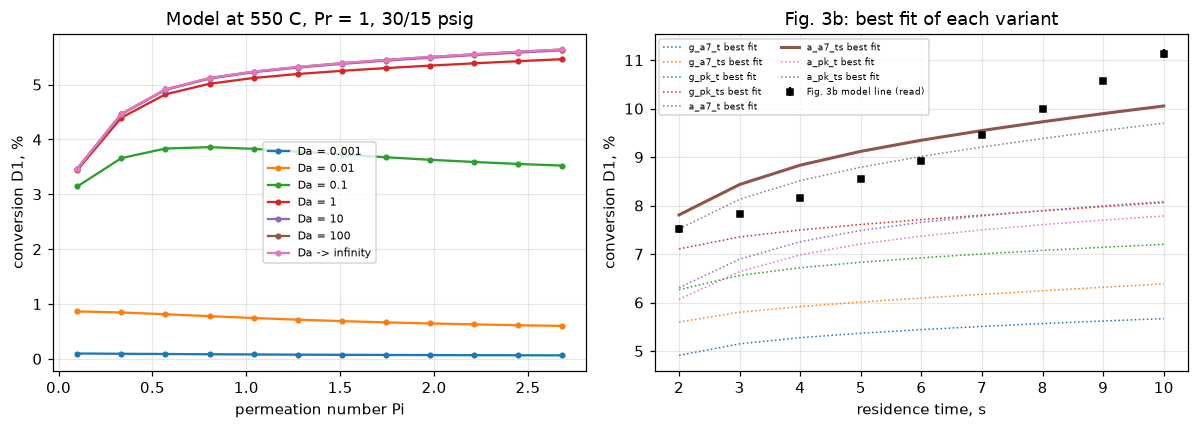

In [14]:
Das, Pis, Xmap = M["_map"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for d_, row_ in zip(Das + ["inf"], Xmap):
    ax[0].plot(Pis, 100 * row_, "-o", ms=3, label=f"Da = {d_:g}" if d_ != "inf" else "Da -> infinity")
ax[0].set(xlabel="permeation number Pi", ylabel="conversion D1, %", title="Model at 550 C, Pr = 1, 30/15 psig")
ax[0].legend(fontsize=7)
tau_, y_, e_ = series("3b", "model")
ax[1].errorbar(tau_, y_, yerr=e_, fmt="ks", ms=4, label="Fig. 3b model line (read)")
for k, (p2, m) in M["_fits"].items():
    ax[1].plot(tau_, m, "-" if k == M["_best"] else ":", lw=2 if k == M["_best"] else 1, label=f"{k} best fit")
ax[1].set(xlabel="residence time, s", ylabel="conversion D1, %", title="Fig. 3b: best fit of each variant")
ax[1].legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

### R4: the test, Fig. 3b read as data

Eight closure variants (reading of "psi" x tabulated or the paper's own $K_p$ x shell
reaction off or on; labels `g`/`a`, `a7`/`pk`, `t`/`ts`), $\Pi$ and $Da$ both proportional
to $\tau$, $Da\to\infty$ (the upper envelope). For each, the $\Pi$ at 2 s that minimises the
largest deviation from the nine nodes of the Fig. 3b model line, bounded below drainage at
10 s. Verdict thresholds fixed in the plan before the run: within 0.18 points of all nine
nodes in some variant, reproduced; above 0.30 in every variant, not reproduced; between,
undecided.

In [15]:
VN = sorted(M["_fits"])
print(f"{'variant':10s} {'sup %':>8s} {'+-':>8s} {'max dev, pt':>12s}")
for k in VN:
    print(f"{k:10s} {M[f'r4_{k}_sup_pct']:8.3f} {M[f'r4_{k}_sup_err_pct']:8.1e} {M[f'r4_{k}_maxdev_pt']:12.3f}")
BG = min((k for k in VN if k.startswith("g_")), key=lambda k: M[f"r4_{k}_maxdev_pt"])   # best variant on the gauge reading
say("**Verdict: <<v>>.** One bound holds for all eight variants: the supremum of the model (the tube at "
    "drainage, $Da\\to\\infty$) is at most <<smax:.2f>> %, <<gapm:.2f>> points below the printed <<y10:.2f>> % at 10 s "
    "(<<gapre:.1f>> times that node's reading error). The best variant (<<b>>) misses the Fig. 3b model "
    "line by up to <<d:.2f>> points (at <<n1:.0f>> s, <<dpr:.1f>> of that node's reading errors) and by up to <<dr:.0f>> "
    "reading errors (at <<n2:.0f>> s); no variant comes within <<m:.2f>> points. The best fit of each variant "
    "sits on the drainage bound. The model rises with falling slope in every variant: <<nc:d>> of <<nw:d>> windows "
    "(second difference at $\\Pi$, 3$\\Pi$ and 5$\\Pi$, the 2, 6 and 10 s nodes, over 200 values of $\\Pi$ per variant) are "
    "convex. In the best variant the second difference over 2, 6 and 10 s is <<md:.3f>> points, where the printed "
    "line's is <<pd:+.3f>>, <<pz:.1f>> times its reading error (the printed line is convex). Locally the "
    "printed curvature is not resolved: <<p2:d>> of 7 one-second differences exceed two reading errors. "
    "In the best variant the supremum is <<sup:.2f>> %, <<gap:.2f>> points below the printed value at 10 s. "
    "On the gauge reading the best variant (<<bg>>) misses by <<gd:.2f>> points and its supremum is <<gs:.2f>> %. "
    "With the same $\\Pi$ the best variant misses "
    "Fig. 3a by <<a:.2f>>, Fig. 3c by <<c:.2f>> and Fig. 2b by <<t:.2f>> points (largest deviations). Other "
    "conversion definitions in the two best variants: D2 <<d2a:.2f>> and <<d2b:.2f>>, D4 <<d4a:.2f>> and "
    "<<d4b:.2f>> points. The four printed model readings of the one shared state (550 C, $Pr$ 1, 2 s, "
    "30/15 psi) spread over <<sp:.2f>> points.",
    v=M["r4_verdict"], b=M["_best"], d=M["r4_best_maxdev_pt"], dr=M["r4_best_maxdev_re"], n1=M["r4_best_maxdev_pt_node_s"],
    n2=M["r4_best_maxdev_re_node_s"], dpr=M["r4_best_maxdev_pt_re"], smax=M["r4_max_sup_over_variants_pct"],
    gapm=M["r4_min_gap_10s_pt"], gapre=M["r4_min_gap_10s_re"], nc=M["r4_n_convex_windows"], nw=M["r4_n_windows"],
    m=M["r4_min_maxdev_over_variants_pt"], md=M["r4_best_d2_wide_pt"], pd=M["r4_printed_d2_wide_pt"], pz=M["r4_printed_d2_wide_sig"], p2=M["r4_printed_n_d2_pos"],
    sup=M[f"r4_{M['_best']}_sup_pct"], gap=M["r4_gap_sup_vs_3b_10s_pt"], y10=series("3b", "model")[1][-1],
    bg=BG, gd=M[f"r4_{BG}_maxdev_pt"], gs=M[f"r4_{BG}_sup_pct"],
    a=M["r4_best_3a_maxdev_pt"], c=M["r4_best_3c_maxdev_pt"], t=M["r4_best_2b_maxdev_pt"],
    d2a=M["r4_best1_D2_maxdev_pt"], d2b=M["r4_best2_D2_maxdev_pt"], d4a=M["r4_best1_D4_maxdev_pt"],
    d4b=M["r4_best2_D4_maxdev_pt"], sp=M["r4_shared_spread_pt"])
say("**The cap.** The tube of the best variant drains at $\\Pi_d$ = <<pdb:.3f>> (the gauge, tube-only test case of R3 "
    "drains at <<pdt:.3f>> at $Da$ = 0.1). At drainage the whole tube content reaches the shell and "
    "equilibrates there, so the supremum of a variant with shell reaction is the sweep-diluted equilibrium at the "
    "shell pressure, $X_{eq,mix}$: in the best variant they differ by <<dx:.1e>> points (the supremum's own "
    "extrapolation error is <<se:.1e>> points). That equilibrium reaches the printed 10 s value only at a "
    "sweep ratio of <<prn:.2f>>, against the printed 1.0. $X$ rises with $Da$ (so $Da\\to\\infty$ is the envelope "
    "used) at <<nr:d>> of <<np:d>> neighbouring map pairs of the gauge variant of R3, and at <<nv:d>> of <<npv:d>> "
    "pairs (9 values of $\\Pi$, $Da$ from 0.01 to 100 and $Da\\to\\infty$) in the variants <<vn>>.",
    pdb=M["r4_best_Pi_d"], pdt=M["r3_Pi_d_DaT"], dx=M["r4_sup_minus_xeq_mix_pt"], se=M[f"r4_{M['_best']}_sup_err_pct"],
    prn=M["r4_Pr_needed_best"], nr=M["r3_map_n_rise_with_Da"], np=M["r3_map_n_pairs"], nv=M["r4_var_n_rise_with_Da"],
    npv=M["r4_var_n_pairs"], vn=", ".join(RISE_VARIANTS))
say("**Routes.** The Fig. 3b test and the suprema run on the local-equilibrium integration ($Da\\to\\infty$) and "
    "scipy's Radau integration. The finite-volume solve (pymrm) checks the best variant at its 6 s node "
    "($\\Pi$ = 3 $\\Pi_2$, $\\Pi_2$ = <<p2:.4f>>, $Da$ = 1e3, 100 to 800 cells): observed orders <<o1:.3f>> to <<o2:.3f>>, "
    "extrapolated $X$ <<x:.5f>> %, which differs from the Radau value at the same $Da$ by <<g:.3f>> of its "
    "extrapolation-error estimate.", p2=M["r4_best_Pi2"], o1=M["r4_fv_best_order_min"], o2=M["r4_fv_best_order_max"],
    x=M["r4_fv_best_extrap_pct"], g=M["r4_fv_best_gap_over_err"])

variant       sup %       +-  max dev, pt
a_a7_t        8.091  8.9e-03        3.054
a_a7_ts      10.071  1.7e-02        1.082
a_pk_t        7.793  8.6e-03        3.351
a_pk_ts       9.716  1.6e-02        1.436
g_a7_t        5.673  5.2e-03        5.468
g_a7_ts       6.392  7.7e-03        4.752
g_pk_t        7.206  6.3e-03        3.937
g_pk_ts       8.071  9.2e-03        3.074


**Verdict: not reproduced.** One bound holds for all eight variants: the supremum of the model (the tube at drainage, $Da\to\infty$) is at most 10.07 %, 1.07 points below the printed 11.14 % at 10 s (12.7 times that node's reading error). The best variant (a_a7_ts) misses the Fig. 3b model line by up to 1.08 points (at 10 s, 12.9 of that node's reading errors) and by up to 16 reading errors (at 9 s); no variant comes within 1.08 points. The best fit of each variant sits on the drainage bound. The model rises with falling slope in every variant: 0 of 1600 windows (second difference at $\Pi$, 3$\Pi$ and 5$\Pi$, the 2, 6 and 10 s nodes, over 200 values of $\Pi$ per variant) are convex. In the best variant the second difference over 2, 6 and 10 s is -0.834 points, where the printed line's is +0.810, 5.6 times its reading error (the printed line is convex). Locally the printed curvature is not resolved: 0 of 7 one-second differences exceed two reading errors. In the best variant the supremum is 10.07 %, 1.07 points below the printed value at 10 s. On the gauge reading the best variant (g_pk_ts) misses by 3.07 points and its supremum is 8.07 %. With the same $\Pi$ the best variant misses Fig. 3a by 0.61, Fig. 3c by 1.12 and Fig. 2b by 2.03 points (largest deviations). Other conversion definitions in the two best variants: D2 2.12 and 2.45, D4 1.79 and 1.89 points. The four printed model readings of the one shared state (550 C, $Pr$ 1, 2 s, 30/15 psi) spread over 0.18 points.

**The cap.** The tube of the best variant drains at $\Pi_d$ = 1.906 (the gauge, tube-only test case of R3 drains at 2.822 at $Da$ = 0.1). At drainage the whole tube content reaches the shell and equilibrates there, so the supremum of a variant with shell reaction is the sweep-diluted equilibrium at the shell pressure, $X_{eq,mix}$: in the best variant they differ by 1.8e-04 points (the supremum's own extrapolation error is 1.7e-02 points). That equilibrium reaches the printed 10 s value only at a sweep ratio of 1.36, against the printed 1.0. $X$ rises with $Da$ (so $Da\to\infty$ is the envelope used) at 72 of 72 neighbouring map pairs of the gauge variant of R3, and at 135 of 135 pairs (9 values of $\Pi$, $Da$ from 0.01 to 100 and $Da\to\infty$) in the variants a_a7_ts, a_a7_t, g_pk_ts.

**Routes.** The Fig. 3b test and the suprema run on the local-equilibrium integration ($Da\to\infty$) and scipy's Radau integration. The finite-volume solve (pymrm) checks the best variant at its 6 s node ($\Pi$ = 3 $\Pi_2$, $\Pi_2$ = 0.3812, $Da$ = 1e3, 100 to 800 cells): observed orders 1.008 to 1.016, extrapolated $X$ 9.34750 %, which differs from the Radau value at the same $Da$ by 0.008 of its extrapolation-error estimate.

### R5: the printed membrane as a permeation number

In [16]:
say("With 40 A pores, a 10 um layer, $R_1$ = 0.35 cm and $\\tau$ = 2 s, eq. 1 gives $\\Pi_E$ = "
    "<<c:.2f>> $\\varepsilon/\\tau_m$ (Knudsen $D_K$ of ethane <<dk:.3e>> m2/s at 550 C). The tube drains at "
    "$Da\\to\\infty$ once $\\varepsilon/\\tau_m$ exceeds <<e2:.4f>> at 2 s and <<e10:.4f>> at 10 s (empty-tube "
    "residence time; a bed voidage multiplies $\\Pi$ by its value). No value of $\\varepsilon/\\tau_m$ is "
    "claimed: the paper prints none.", c=M["r5_PiE_per_eps_tau"], dk=M["r5_DK_E_m2_s"],
    e2=M["r5_eps_tau_drain_2s"], e10=M["r5_eps_tau_drain_10s"])

With 40 A pores, a 10 um layer, $R_1$ = 0.35 cm and $\tau$ = 2 s, eq. 1 gives $\Pi_E$ = 116.17 $\varepsilon/\tau_m$ (Knudsen $D_K$ of ethane 1.015e-06 m2/s at 550 C). The tube drains at $Da\to\infty$ once $\varepsilon/\tau_m$ exceeds 0.0247 at 2 s and 0.0049 at 10 s (empty-tube residence time; a bed voidage multiplies $\Pi$ by its value). No value of $\varepsilon/\tau_m$ is claimed: the paper prints none.

## Validation

In [17]:
say("Closed forms (E17): the packed-bed quadrature and the IVP at $\\Pi$ = 0 agree to below 1e-8 (here "
    "<<pb:.0e>>); the exchange closed form and the IVP to below 1e-9 at 11 nodes (here <<ex:.0e>>); the FV "
    "drainage root with equal permeances, $Da$ = 0, is (1 - 0.01)/(1 - $\\beta$) to below 1e-9 (here <<ld:.0e>>; "
    "the tube flow is linear, which upwind FV integrates exactly). "
    "The $Da\\to\\infty$ route against the full model: gap <<g3:.1e>> at $Da$ = 1e3, falling by a factor "
    "10^<<o1:.2f>> and 10^<<o2:.2f>> per decade of $Da$ (theory: 10^1).",
    pb=M["v1_pb_quad_vs_ivp"], ex=M["v1_exchange_ivp_gap"], ld=M["v1_lin_drain_fv_gap"], g3=M["v1_E16_gap_1e3"],
    o1=M["v1_E16_gap_order"], o2=M["v1_E16_gap_order_2"])
say("Atom balances (C, H, Ar) on the FV faces close to below 1e-12 on every grid (here <<ab:.0e>>) (a discrete identity of the "
    "conservative scheme). Grid ladders 100 to 1600 cells: orders <<a1:.3f>> to <<a2:.3f>> for X at T, "
    "<<b1:.3f>> to <<b2:.3f>> for the exchange case, <<c1:.3f>> to <<c2:.3f>> for $\\Pi_d$ (theory 1). "
    "Extrapolated X at T is <<xt:.5f>> % with error estimate <<et:.1e>>; it lies within 10 error estimates of "
    "the IVP (here <<gt:.0e>>); the extrapolated exchange outlet misses the closed form by below 1e-5 (here "
    "<<eg:.0e>>); the extrapolated $\\Pi_d$ <<pd:.5f>> lies within 10 error estimates of the IVP root (here "
    "<<gd:.0e>>). A second LU column ordering moves X at 1600 cells by below 1e-12 (here <<cg:.0e>>); the "
    "finest grid difference is more than 1e3 times that (here <<fr:.0e>>).",
    ab=M["v2_atom_balance_max"], a1=M["v3_XT_order_min"], a2=M["v3_XT_order_max"], b1=M["v3_exch_order_min"],
    b2=M["v3_exch_order_max"], c1=M["v3_Pid_order_min"], c2=M["v3_Pid_order_max"], xt=M["v3_XT_extrap_pct"],
    et=M["v3_XT_err_est"], gt=M["v3_XT_gap_over_err"], eg=M["v3_exch_ext_gap"], pd=M["v3_Pid_extrap"],
    gd=M["v3_Pid_gap_over_err"], cg=M["v3_companion_gap"], fr=M["v3_finest_diff_over_roundoff"])

Closed forms (E17): the packed-bed quadrature and the IVP at $\Pi$ = 0 agree to below 1e-8 (here 3e-16); the exchange closed form and the IVP to below 1e-9 at 11 nodes (here 3e-14); the FV drainage root with equal permeances, $Da$ = 0, is (1 - 0.01)/(1 - $\beta$) to below 1e-9 (here 4e-16; the tube flow is linear, which upwind FV integrates exactly). The $Da\to\infty$ route against the full model: gap 8.2e-07 at $Da$ = 1e3, falling by a factor 10^1.00 and 10^1.00 per decade of $Da$ (theory: 10^1).

Atom balances (C, H, Ar) on the FV faces close to below 1e-12 on every grid (here 2e-15) (a discrete identity of the conservative scheme). Grid ladders 100 to 1600 cells: orders 0.995 to 0.999 for X at T, 0.996 to 0.999 for the exchange case, 0.972 to 0.993 for $\Pi_d$ (theory 1). Extrapolated X at T is 3.80557 % with error estimate 7.2e-06; it lies within 10 error estimates of the IVP (here 1e-03); the extrapolated exchange outlet misses the closed form by below 1e-5 (here 5e-08); the extrapolated $\Pi_d$ 2.82237 lies within 10 error estimates of the IVP root (here 7e-03). A second LU column ordering moves X at 1600 cells by below 1e-12 (here 8e-17); the finest grid difference is more than 1e3 times that (here 7e+10).

### The claims

In [18]:
RT = 1e-6
STRUCTURAL = {"r2_n_symbols": "number of digitised symbols", "r1_n_2a_lines": "number of Fig. 2a line readings",
              "r1_n_dense_lines": "number of dense line readings", "r3_map_n_pairs": "6 x 12 map pairs", "r4_n_windows": "8 variants x 200 windows",
              "r4_var_n_pairs": "3 variants x 9 Pi x 5 Da pairs",
              "r3_lever_n_points": "20 Pi values", "r3_lever_tau_n_points": "Pi values with room for a 1 % step", "r3_Pi_d_closed_q1": "1/(1 - beta), a formula",
              "v2_atom_balance_max": "the conservative scheme closes C, H, Ar by construction"}
BOUNDS = {
    "v1_pb_quad_vs_ivp": (None, 1e-8, "tolerance", "quad epsrel 1e-13 against Radau rtol 1e-12"),
    "v1_exchange_ivp_gap": (None, 1e-9, "tolerance", "Radau rtol 1e-12"),
    "v1_lin_drain_fv_gap": (None, 1e-9, "tolerance", "linear profile exact in upwind FV; root xtol 1e-12"),
    "v1_E16_gap_order": (0.8, 1.2, "theory", "the Da -> infinity remainder is O(1/Da)"),
    "v1_E16_gap_order_2": (0.8, 1.2, "theory", "the Da -> infinity remainder is O(1/Da)"),
    "v2_atom_balance_max": (None, 1e-12, "identity", "conservative fluxes and an atom-conserving source"),
    "v3_XT_order_min": (0.9, 1.1, "theory", "first-order upwind"), "v3_XT_order_max": (0.9, 1.1, "theory", "first-order upwind"),
    "v3_exch_order_min": (0.9, 1.1, "theory", "first-order upwind"), "v3_exch_order_max": (0.9, 1.1, "theory", "first-order upwind"),
    "v3_Pid_order_min": (0.9, 1.1, "theory", "first-order upwind"), "v3_Pid_order_max": (0.9, 1.1, "theory", "first-order upwind"),
    "v3_XT_gap_over_err": (None, 10.0, "chosen", "plan stop rule: FV within 10 extrapolation-error estimates of the IVP"),
    "v3_Pid_gap_over_err": (None, 10.0, "chosen", "plan stop rule: FV within 10 extrapolation-error estimates of the IVP"),
    "v3_exch_ext_gap": (None, 1e-5, "chosen", "Richardson remainder O(h^2) at 1600 cells"),
    "v3_companion_gap": (None, 1e-12, "tolerance", "round-off of the newton solve"),
    "v3_finest_diff_over_roundoff": (1e3, None, "chosen", "the finest difference above its round-off by 1e3"),
    "r4_fv_best_order_min": (0.9, 1.1, "theory", "first-order upwind"), "r4_fv_best_order_max": (0.9, 1.1, "theory", "first-order upwind"),
    "r4_fv_best_gap_over_err": (None, 10.0, "chosen", "plan stop rule: FV within 10 extrapolation-error estimates of the IVP"),
}
COUNTS = {"r1_n_2a_within_2re": 1.0, "r1_n_dense_below": 1.0, "r2_n_above_shell": 1.0, "r2_n_above_tube": 1.0,
          "r2_n_above_mix": 1.0, "r2_n_above_shell_abs": 1.0, "r2_n_above_tube_abs": 1.0, "r2_n_above_mix_abs": 1.0, "r3_map_n_rise_with_Da": 0.0, "r4_n_convex_windows": 0.0, "r4_var_n_rise_with_Da": 0.0, "r4_printed_n_d2_pos": 1.0}
for tag in ("tube", "rx"):
    for lv in ("pr", "pf", "tau"):
        COUNTS[f"r3_lever_{lv}_pos_{tag}"] = 0.0


def register(M):
    for name, v in M.items():
        if name.startswith("_") or "__" in name or name in ("r4_verdict",):
            continue
        if name in BOUNDS:
            lo, hi, basis, note = BOUNDS[name]
            claims.bound(name, v, min=lo, max=hi, basis=basis, structural=name in STRUCTURAL, note=note)
        elif name == "r4_sup_minus_xeq_mix_pt":
            claims.bound(name, v, min=None, max=M[f"r4_{M['_best']}_sup_err_pct"], basis="tolerance",
                         note="the supremum's extrapolation-error estimate in eps_d (percent = points)")
        elif name in COUNTS:
            vals = np.asarray(M[name + "__vals"], float)
            thr = 1.0 if COUNTS[name] == 1.0 else 0.0
            claims.exact(name, v, margin=float(np.min(np.abs(vals - thr))), min_margin=0.0,
                         note=f"count of {vals.size}, threshold {thr}")
        elif name in STRUCTURAL:
            if isinstance(v, (int, np.integer)):
                claims.exact(name, v, structural=True, note=STRUCTURAL[name])
            else:
                claims.value(name, v, rtol=RT, note="structural: " + STRUCTURAL[name])
                claims.metrics[name]["structural"] = True
        elif isinstance(v, (int, np.integer)):
            claims.exact(name, v)
        else:
            claims.value(name, v, rtol=RT)
    claims.exact("r4_verdict", M["r4_verdict"], margin=M["r4_verdict__margin"], min_margin=0.0,
                 note="smallest distance of the best variant's deviation to a threshold (pt)")
    claims.exact("r4_best_variant", M["_best"])


register(M)

### The break table

Every non-structural number registered above has a row that moves it. Each row injects
one defect through `Cfg` (a thermodynamic term, a feed, a reading of the paper, a
closure, a parameter passed to one route only, a grid or order setting) and reruns the
parts of the study the defect reaches; the claims it fails are counted. Every row
records finite values.

In [19]:
DEFECTS = [
    ("Cp terms dropped from K_p", replace(C0, cp=False), ("r1", "r2", "r3", "r4", "r4fv")),
    ("dense feed without its H2 co-feed", replace(C0, h2_zero=True), ("r1", "r2", "r3", "r4", "r4fv")),
    ("absolute pressures in place of gauge", replace(C0, basis="abs"), ("r1", "r2", "r4", "r4fv")),
    ("dilute feed in the dense rows", replace(C0, dense_as_dilute=True), ("r1",)),
    ("Fig. 3a axis shifted one grid interval (2 pt)", replace(C0, fig3a_shift=2.0), ("r1", "r4")),
    ("q_j = 1 for every species", replace(C0, q_equal=True), ("r3", "r4", "r4fv", "r5")),
    ("beta = 1 for the levers", replace(C0, beta_one=True), ("r3",)),
    ("tau scaling applied to Da only", replace(C0, tau_scaling="da"), ("r4", "r4fv")),
    ("verdict thresholds ten times wider", replace(C0, v_scale=10.0), ("r4",)),
    ("ladder refined by 1.5, orders computed for 2", replace(C0, order_ratio=1.5), ("v", "r4", "r4fv")),
    ("pore radius for diameter", replace(C0, pore="radius"), ("r5",)),
    ("steam reforming at 10 psia", replace(C0, smr_basis="abs"), ("r1",)),
    ("Fig. 4b read as CO2/(CO + CO2)", replace(C0, m4="over_COx"), ("r1",)),
    ("packed-bed quadrature with K 1 % high", replace(C0, pb_kmult=1.01), ("v",)),
    ("exchange closed form at half the sweep ratio", replace(C0, exch_pr=0.5), ("v",)),
    ("linear drainage closed form with the absolute beta", replace(C0, lin_beta="abs"), ("v",)),
    ("Da -> infinity route with K 0.1 % high", replace(C0, le_kmult=1.001), ("v",)),
    ("FV ladders at Da 50 % high", replace(C0, fv_da_mult=1.5), ("v", "r4", "r4fv")),
    ("finite-volume check of the best variant at Pi 1 % high", replace(C0, fv_pi_mult=1.01), ("r4", "r4fv")),
    ("closed-form sweep-diluted equilibrium at 0.9 times the sweep ratio", replace(C0, mix_pr=0.9), ("r4",)),
    ("round-off companion at Pi 1e-4 high", replace(C0, comp_pi_mult=1 + 1e-4), ("v",)),
    ("levers differenced in the wrong direction", replace(C0, lever_sign=-1.0), ("r3",)),
    ("map Da axis in reverse order", replace(C0, map_reverse=True), ("r3", "r4b")),
    ("Fig. 3b conversion axis read as logarithmic", replace(C0, fig3b_axis="log"), ("r4", "r4fv")),
    ("Pi proportional to tau squared", replace(C0, tau_scaling="square"), ("r4", "r4b", "r4fv")),
]
CONTROLS = [("control: clean rerun of R1, R2 and R5", C0, ("r1", "r2", "r5"))]
claims.define_rows([r_ for r_, _, _ in CONTROLS + DEFECTS])
BREAK = []
for row, c_, parts in CONTROLS + DEFECTS:
    with np.errstate(divide="ignore", invalid="ignore"):
        Mb = study(c_, parts)
    if "r4_verdict" in Mb:
        Mb["r4_best_variant"] = Mb["_best"]
    for name in claims.metrics:
        if claims.metrics[name].get("structural") or name not in Mb:
            continue
        x_ = Mb[name]
        if isinstance(x_, (float, np.floating)) and not np.isfinite(x_):
            continue
        BREAK.append((row, name, claims.breaks(row, name, x_)))

sweep ratio reaching the 10 s conversion: 0 roots on [0.5, 20.0] (no sign change in the scanned range)


In [20]:
by_row = {}
for r_, m_, c_ in BREAK:
    by_row.setdefault(r_, []).append(c_)
_bad = [r_ for r_ in by_row if r_.startswith("control") and any(by_row[r_])]
assert not _bad, f"a control row failed a claim: {_bad}"
print(f"{'injected defect':<52} {'claims failed':>13}")
for r_, cs in by_row.items():
    print(f"{r_[:52]:<52} {sum(cs):13d}")
_caught = {m_ for r_, m_, c_ in BREAK if c_}
_open = sorted(k_ for k_ in claims.metrics if k_ not in _caught and not claims.metrics[k_].get("structural"))
print(f"\n{len(by_row)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least one row; "
      f"open: {', '.join(_open) or 'none'}")

injected defect                                      claims failed
control: clean rerun of R1, R2 and R5                            0
Cp terms dropped from K_p                                       72
dense feed without its H2 co-feed                               76
absolute pressures in place of gauge                            42
dilute feed in the dense rows                                   10
Fig. 3a axis shifted one grid interval (2 pt)                   46
q_j = 1 for every species                                       55
beta = 1 for the levers                                          1
tau scaling applied to Da only                                  16
verdict thresholds ten times wider                               1
ladder refined by 1.5, orders computed for 2                    11
pore radius for diameter                                         4
steam reforming at 10 psia                                       6
Fig. 4b read as CO2/(CO + CO2)                                

## What pymrm adds

pymrm contributes the reactor solve and the checks. The Fig. 3b test and the suprema, the page's
finding, run on scipy routes (the local-equilibrium integration and Radau); the pymrm solve
confirms the best variant at its 6 s node and carries the test condition, the drainage
threshold and the grid ladders. `MembraneReactor` carries two
plug-flow channels with four molar flows each on one axial grid: a `BlockLayout` of the
tube and shell blocks, each convected by a constant unit-velocity upwind operator
(`construct_convflux_upwind`, `construct_div`), inlet values in the `bc`, outlets
`{"outflow": True}` read with `compute_boundary_values`, the pointwise permeation and
reaction source through `NumJac`, and `newton` on the sparse Jacobian with a lower bound on
every flow. Its conservative form closes the atom balances to round-off, which the IVP
route does only to its tolerance. `pymrm.checks.find_roots` gives the drainage thresholds,
the lever reversal and the check-value roots, each the only root on its range;
`observed_orders` the grid orders and the extrapolations in the grid and in the drainage
threshold. The equilibrium algebra, the thermodynamics, the local-equilibrium limit and
the figure reading are numpy and scipy. The page reproduces no published number: it tests
printed model curves against the printed model, closed by the named assumptions.

## Reuse

- `model.source` is the isothermal two-channel membrane reactor for any permeance ratios
  `q`: Knudsen here, `q` with one non-zero entry for a hydrogen-selective wall (page `H1.4`).
- `model.LocalEquilibrium` gives the fast-reaction envelope for every $\Pi$ from one
  integration; use it to bound a membrane reactor before fitting kinetics.
- With a porous wall at a fixed pressure difference, check drainage ($\Pi_d$, E18) before
  reading a high conversion as selectivity: the tube empties into the shell.
- Related pages: `H1.4` (Pd membrane, equilibrium shift), `H1.1` (Sieverts permeation),
  `D1.1` (packed-bed models), `H1.7` (solution-diffusion).

In [21]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for H1.5:
  r1_K_823_bar                   = 0.009281         value  rtol 1e-06
  r1_dH_823_kJ                   = 142.87           value  rtol 1e-06
  r1_rms_2a_gauge                = 0.65312          value  rtol 1e-06
  r1_rms_2a_abs                  = 5.6555           value  rtol 1e-06
  r1_rms_ratio_2a                = 8.6591           value  rtol 1e-06
  r1_n_2a_lines                  = 18               exact  exact
  r1_n_2a_within_2re             = 12               exact  exact, margin 0.0956
  r1_rms_dense_gauge             = 1.1923           value  rtol 1e-06
  r1_mean_dense_gauge            = -1.1356          value  rtol 1e-06
  r1_rms_dense_abs               = 1.4095           value  rtol 1e-06
  r1_n_dense_lines               = 72               exact  exact
  r1_n_dense_below               = 72               exact  exact, margin 0.38
  r1_fit_yH_pct                  = 4.4693           value  rtol 1e-06
  r1_fit_yH_rms                  = 0.28407          value  rtol 1